<a href="https://colab.research.google.com/github/Maipatatohoon/bioinsight-360/blob/main/BioInsight_360_Colab_Runbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BioInsight 360 — Google Colab Runbook

This notebook turns a free Colab runtime into both the **scientific engine** and the
**headless compute worker** for BioInsight 360, and gives your deployed Vercel frontend a
**public backend URL** to talk to.

## Two modes (run either, or both)

| Mode | What it does | Needs |
|------|--------------|-------|
| **A — Phase 3 validation** | Runs the real R/Bioconductor engines (DESeq2, edgeR, limma-voom) on a counts matrix and writes DEG tables + plots. | Nothing external. Run this to produce the Phase 3 deliverable. |
| **B — Live backend + worker** | Starts the FastAPI backend, exposes it on a public HTTPS URL (cloudflared quick tunnel), and runs the polling worker so jobs submitted from your web app get computed here. | A frontend that points at the printed URL. |

## Before you start — three things the old runbook got wrong
1. **The worker is not in the frontend repo.** `bioinsight-360` stores `backend/` only as a
   bare gitlink (no `.gitmodules`), so cloning it gives an **empty** `backend/` folder. The
   real code lives in **`Maipatatohoon/bioinsight-backend`** — this notebook clones that.
2. **Env var names.** The code reads **`BIOINSIGHT_BACKEND_URL`** and
   **`BIOINSIGHT_WORKER_TOKEN`** (not `BACKEND_URL` / `WORKER_TOKEN`).
3. **Colab does not persist between sessions.** Installs and the tunnel URL are gone next
   time; re-run from the top.

> Runtime → Change runtime type → **CPU is fine**. The whole notebook takes ~10–15 min the
> first time (mostly R package installation).

## 0. Configuration
Edit the values below, then run the cell.

In [ ]:
#@title Configuration { display-mode: "form" }
BACKEND_REPO   = "https://github.com/Maipatatohoon/bioinsight-backend.git"  # worker + R engines live here
FRONTEND_REPO  = "Maipatatohoon/bioinsight-360"      # only used for demo data
FRONTEND_BRANCH = "main"
WORKDIR        = "/content/bioinsight-backend"
RESULTS_DIR    = "/content/bioinsight_results"

# Mode B settings
SERVE_BACKEND  = True                 # start FastAPI + public tunnel
RUN_WORKER     = True                 # run the polling worker against that URL
WORKER_TOKEN   = "dev-token-123"      # must match BIOINSIGHT_WORKER_TOKEN on the backend
MANUAL_BACKEND_URL = ""               # set if you already have a public backend URL

import os, sys
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Backend repo :", BACKEND_REPO)
print("Workdir      :", WORKDIR)
print("Results dir  :", RESULTS_DIR)
print("Python       :", sys.version.split()[0])

## 1. Install system + R + Bioconductor prerequisites
This is the slow cell (~10–15 min the first time). Colab runs as root, so `apt-get` works.

In [ ]:
%%bash
set -e
apt-get -qq update
apt-get -qq install -y r-base libcurl4-openssl-dev libssl-dev libxml2-dev libglpk-dev >/dev/null
echo "R installed:"; R --version | head -1

In [ ]:
%%bash
set -e
Rscript -e 'install.packages("BiocManager", repos="https://cloud.r-project.org")'
# Bioconductor packages download/compile; this is the long part.
Rscript -e 'BiocManager::install(c("DESeq2","edgeR","limma"), ask=FALSE, update=FALSE)'
echo "--- available engines ---"
Rscript -e 'cat(intersect(rownames(installed.packages()), c("DESeq2","edgeR","limma")), sep="\n")'

Creating a new generic function for ‘aperm’ in package ‘BiocGenerics’
Creating a new generic function for ‘append’ in package ‘BiocGenerics’
Creating a new generic function for ‘as.data.frame’ in package ‘BiocGenerics’
Creating a new generic function for ‘cbind’ in package ‘BiocGenerics’
Creating a new generic function for ‘rbind’ in package ‘BiocGenerics’
Creating a new generic function for ‘do.call’ in package ‘BiocGenerics’
Creating a new generic function for ‘duplicated’ in package ‘BiocGenerics’
Creating a new generic function for ‘anyDuplicated’ in package ‘BiocGenerics’
Creating a new generic function for ‘eval’ in package ‘BiocGenerics’
Creating a new generic function for ‘pmax’ in package ‘BiocGenerics’
Creating a new generic function for ‘pmin’ in package ‘BiocGenerics’
Creating a new generic function for ‘pmax.int’ in package ‘BiocGenerics’
Creating a new generic function for ‘pmin.int’ in package ‘BiocGenerics’
Creating a new generic function for ‘Reduce’ in package ‘BiocGe

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/BiocManager_1.30.27.tar.gz'
Content type 'application/x-gzip' length 752490 bytes (734 KB)
downloaded 734 KB

* installing *source* package ‘BiocManager’ ...
** this is package ‘BiocManager’ version ‘1.30.27’
** package ‘BiocManager’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
*** copying figures
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (BiocManager)

The downloaded source packages are in
	‘/tmp/RtmpVIRthT/downloaded_packages’
'getOption("repos")' replaces Bioconductor standard repositories, see
'he

In [ ]:
# Python deps for the FastAPI backend + worker
!pip -q install fastapi "uvicorn[standard]" pandas numpy python-multipart pydantic scikit-learn requests 2>&1 | tail -2
print("python deps ready")

python deps ready


## 2. Get the backend code

In [ ]:
import os, subprocess
if os.path.isdir(os.path.join(WORKDIR, ".git")):
    print(subprocess.run(["git", "-C", WORKDIR, "pull", "--ff-only"], capture_output=True, text=True).stdout)
else:
    print(subprocess.run(["git", "clone", "--depth", "1", BACKEND_REPO, WORKDIR], capture_output=True, text=True).stdout)

print(subprocess.run(["bash", "-lc", f"find {WORKDIR} -maxdepth 3 \\( -name '*.R' -o -name 'colab_worker.py' \\)"],
                     capture_output=True, text=True).stdout)


/content/bioinsight-backend/workers/colab_worker.py
/content/bioinsight-backend/app/limma/limma_script.R
/content/bioinsight-backend/app/deseq2/deseq2_script.R
/content/bioinsight-backend/app/edger/edger_script.R



## 3. Mode A — Phase 3 scientific validation (standalone)

Runs the **real** DESeq2 / edgeR / limma-voom scripts on a counts matrix and writes
per-engine TSV files plus MA / volcano / PCA plots. This is the Phase 3 deliverable and
needs no backend.

**Data:** by default it downloads the bundled 200-gene × 8-sample demo matrix
(GSE52778-shaped). To use your own data, run the notebook as-is until the upload fallback,
or just replace `COUNTS` / `META` paths with your files.

In [ ]:
# 3a. Get demo data (or upload your own)
import os, urllib.request
COUNTS = os.path.join(RESULTS_DIR, "counts.csv")
META   = os.path.join(RESULTS_DIR, "metadata.csv")

for local_name, dest in [("demo_counts.csv", COUNTS), ("demo_metadata.csv", META)]:
    url = f"https://raw.githubusercontent.com/{FRONTEND_REPO}/{FRONTEND_BRANCH}/frontend/public/data/{local_name}"
    try:
        urllib.request.urlretrieve(url, dest)
        print("downloaded", url)
    except Exception as e:
        print("download failed:", e)

if not os.path.exists(COUNTS):
    print("No demo data found. Upload your own counts (genes x samples) and metadata (sample,group):")
    from google.colab import files
    up = files.upload()
    for name in up:
        if "meta" in name.lower():
            os.rename(name, META)
        else:
            os.rename(name, COUNTS)

import pandas as pd
print("\nCounts:", pd.read_csv(COUNTS).shape, "| Metadata:", pd.read_csv(META).shape)
print(pd.read_csv(META).head())

downloaded https://raw.githubusercontent.com/Maipatatohoon/bioinsight-360/main/frontend/public/data/demo_counts.csv
downloaded https://raw.githubusercontent.com/Maipatatohoon/bioinsight-360/main/frontend/public/data/demo_metadata.csv

Counts: (200, 9) | Metadata: (8, 2)
       sample    group
0  SRR1039508  CONTROL
1  SRR1039512  CONTROL
2  SRR1039516  CONTROL
3  SRR1039520  CONTROL
4  SRR1039509  TREATED


In [ ]:
# 3b. Run all three engines
import os, subprocess, pandas as pd

def run_engine(engine, script_relpath, counts, meta, design="~ condition", contrast=""):
    out = os.path.join(RESULTS_DIR, f"{engine}_results.tsv")
    script = os.path.join(WORKDIR, script_relpath)
    cmd = ["Rscript", script, "--counts", counts, "--meta", meta, "--out", out,
           "--design", design, "--contrast", contrast]
    print(f"\n=== {engine} ===")
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print("FAILED:\n", r.stderr[-2000:])
        return None
    print(r.stdout[-1000:])
    df = pd.read_csv(out)
    print(df.head())
    sig = df[df["padj"].notna() & (df["padj"] < 0.05)] if "padj" in df else df.iloc[0:0]
    print(f"{engine}: {len(df)} genes tested, {len(sig)} with padj < 0.05")
    return df

scripts = {
    "deseq2": "app/deseq2/deseq2_script.R",
    "edger":  "app/edger/edger_script.R",
    "limma":  "app/limma/limma_script.R",
}
results = {name: run_engine(name, path, COUNTS, META) for name, path in scripts.items()}
print("\nDone. Files in", RESULTS_DIR)


=== deseq2 ===
FAILED:
 Error in library(argparse) : there is no package called ‘argparse’
Calls: suppressPackageStartupMessages -> withCallingHandlers -> library
Execution halted


=== edger ===
FAILED:
 Error in library(argparse) : there is no package called ‘argparse’
Calls: suppressPackageStartupMessages -> withCallingHandlers -> library
Execution halted


=== limma ===
FAILED:
 Error in library(argparse) : there is no package called ‘argparse’
Calls: suppressPackageStartupMessages -> withCallingHandlers -> library
Execution halted


Done. Files in /content/bioinsight_results


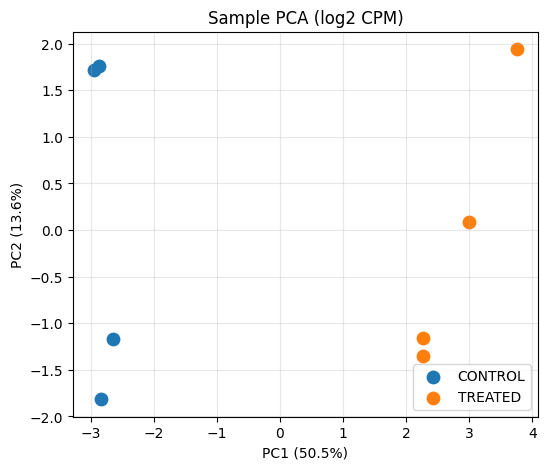

In [ ]:
# 3c. Visualise (Volcano + MA per engine, PCA of samples)
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

for name, df in results.items():
    if df is None or "log2FoldChange" not in df or "pvalue" not in df:
        continue
    d = df.dropna(subset=["log2FoldChange", "pvalue"]).copy()
    d["neglog10p"] = -np.log10(d["pvalue"].clip(lower=1e-300))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(d["log2FoldChange"], d["neglog10p"], s=10, alpha=0.6)
    ax[0].axvline(1, ls="--", c="grey"); ax[0].axvline(-1, ls="--", c="grey")
    ax[0].axhline(-np.log10(0.05), ls="--", c="red")
    ax[0].set(title=f"{name}: Volcano", xlabel="log2FC", ylabel="-log10 p")
    ax[1].scatter(d["log2FoldChange"], d["neglog10p"], s=10, alpha=0.6)
    ax[1].set(title=f"{name}: MA-style", xlabel="log2FC", ylabel="-log10 p")
    plt.tight_layout(); plt.show()

counts = pd.read_csv(COUNTS, index_col=0)
meta = pd.read_csv(META, index_col=0)
cpm = counts.div(counts.sum(axis=0), axis=1) * 1e6
X = np.log2(cpm + 1).T
X = X.loc[:, X.var(axis=0) > 0]
Xc = X - X.mean()
U, S, Vt = np.linalg.svd(Xc.values, full_matrices=False)
pcs = U[:, :2] * S[:2]
var = (S**2 / (S**2).sum())[:2] * 100
groups = meta.iloc[:, 0].astype(str)
plt.figure(figsize=(6, 5))
for g in groups.unique():
    m = (groups == g).values
    plt.scatter(pcs[m, 0], pcs[m, 1], label=g, s=80)
plt.xlabel(f"PC1 ({var[0]:.1f}%)"); plt.ylabel(f"PC2 ({var[1]:.1f}%)")
plt.title("Sample PCA (log2 CPM)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
# 3d. Zip (and download) the Phase 3 deliverable
import shutil, os
zip_path = shutil.make_archive("/content/bioinsight_phase3_results", "zip", RESULTS_DIR)
print("Created", zip_path, "->", os.path.getsize(zip_path), "bytes")
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Download manually from the Colab file browser:", zip_path)

Created /content/bioinsight_phase3_results.zip -> 4752 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Mode B — Live backend + public URL + headless worker

1. Start the FastAPI backend on `:8000`.
2. Expose it publicly with a **cloudflared quick tunnel** (no account needed) — this is the
   URL your web app uses.
3. Run the polling worker so jobs from the frontend are computed by the engines above.

> If `SERVE_BACKEND` / `RUN_WORKER` are `False` in section 0, the matching cells are skipped.

In [ ]:
# 4a. Start the FastAPI backend in the background
import os, time, subprocess, requests

if SERVE_BACKEND:
    log = open("/content/backend.log", "w")
    env = dict(os.environ, BIOINSIGHT_WORKER_TOKEN=WORKER_TOKEN,
               BIOINSIGHT_DB_PATH="/content/bioinsight_jobs.db")
    proc = subprocess.Popen(["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"],
                            cwd=WORKDIR, stdout=log, stderr=subprocess.STDOUT, env=env)
    time.sleep(8)
    try:
        print("local health:", requests.get("http://localhost:8000/health", timeout=5).json())
    except Exception as e:
        print("backend did not start:", e)
        print(open("/content/backend.log").read()[-2000:])
else:
    print("SERVE_BACKEND is False; skipping.")

local health: {'status': 'healthy', 'service': 'bioinsight-backend'}


In [ ]:
# 4b. Public HTTPS tunnel (cloudflared quick tunnel — no account required)
import os, re, time, stat, subprocess, requests

PUBLIC_BACKEND_URL = (MANUAL_BACKEND_URL or "").strip()
CF_BIN = "/content/cloudflared"
CF_LOG = "/content/cloudflared.log"


def _download_cloudflared():
    import urllib.request
    url = ("https://github.com/cloudflare/cloudflared/releases/latest/download/"
           "cloudflared-linux-amd64")
    urllib.request.urlretrieve(url, CF_BIN)
    os.chmod(CF_BIN, os.stat(CF_BIN).st_mode | stat.S_IEXEC)
    print(subprocess.run([CF_BIN, "--version"], capture_output=True, text=True).stdout.strip())


if SERVE_BACKEND and not PUBLIC_BACKEND_URL:
    # 0) the backend must be up first (cell 4a)
    try:
        print("local health:", requests.get("http://localhost:8000/health", timeout=5).json())
    except Exception as e:
        print("!! BACKEND NOT UP on localhost:8000 ->", e)
        print("   Re-run cell 4a (start the backend) before this cell.")

    # 1) fetch cloudflared (into /content, no root needed)
    if not os.path.exists(CF_BIN):
        try:
            _download_cloudflared()
        except Exception as e:
            print("!! cloudflared download failed:", e)

    # 2) start a quick tunnel; cloudflared logs the public URL to its output
    if os.path.exists(CF_BIN):
        log = open(CF_LOG, "w")
        subprocess.Popen(
            [CF_BIN, "tunnel", "--url", "http://localhost:8000", "--no-autoupdate"],
            stdout=log, stderr=subprocess.STDOUT,
        )
        for _ in range(90):
            time.sleep(1)
            try:
                txt = open(CF_LOG).read()
            except Exception:
                txt = ""
            m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", txt)
            if m:
                PUBLIC_BACKEND_URL = m.group(0)
                break
        if not PUBLIC_BACKEND_URL:
            print("!! No tunnel URL appeared. Last cloudflared log lines:")
            try:
                print(open(CF_LOG).read()[-1500:])
            except Exception:
                pass

print("PUBLIC_BACKEND_URL =", PUBLIC_BACKEND_URL or "(none)")
if PUBLIC_BACKEND_URL:
    try:
        print("public health:", requests.get(PUBLIC_BACKEND_URL + "/health", timeout=20).json())
    except Exception as e:
        print("public health check failed:", e)
    print("\n>>> Connect the deployed site (no redeploy needed):")
    print("    Navbar -> Backend -> paste the URL above -> Test & Save")


PUBLIC_BACKEND_URL = https://exp-clinton-agents-quantitative.trycloudflare.com
public health check failed: HTTPSConnectionPool(host='exp-clinton-agents-quantitative.trycloudflare.com', port=443): Max retries exceeded with url: /health (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7bdacb17eba0>: Failed to resolve 'exp-clinton-agents-quantitative.trycloudflare.com' ([Errno -2] Name or service not known)"))


### ➜ Connect your web app

**Recommended — no redeploy needed** (the Colab URL changes each session):

1. Open your deployed site.
2. Click **Backend** in the navbar.
3. Paste the `PUBLIC_BACKEND_URL` printed above and click **Test & Save**.
   The status dot turns green once the backend responds. The URL is stored in that browser
   and used immediately.

**Alternative — bake it in at build time:** set `NEXT_PUBLIC_BACKEND_URL = <that URL>` in
Vercel → Settings → Environment Variables, then **Redeploy**. (`NEXT_PUBLIC_*` is baked in
at build time, so a redeploy is required after any change.)

The backend allows all origins, so no CORS config is needed.


In [ ]:
# 4c. Run the headless worker (blocking; logs stream below — interrupt the cell to stop)
import os, sys, subprocess, requests

PUBLIC_BACKEND_URL = globals().get("PUBLIC_BACKEND_URL", "").strip()

if not RUN_WORKER:
    print("RUN_WORKER is False; skipping worker loop.")
elif not PUBLIC_BACKEND_URL:
    print("No PUBLIC_BACKEND_URL yet — re-run cell 4b (the tunnel) first, then run this cell.")
else:
    try:
        print("backend:", requests.get(PUBLIC_BACKEND_URL + "/health", timeout=15).json())
    except Exception as e:
        print("!! Backend not reachable at", PUBLIC_BACKEND_URL, "->", e)
        print("   Re-run 4a and 4b.")
    env = dict(os.environ,
               BIOINSIGHT_BACKEND_URL=PUBLIC_BACKEND_URL,
               BIOINSIGHT_WORKER_TOKEN=WORKER_TOKEN)
    subprocess.run([sys.executable, "workers/colab_worker.py"], cwd=WORKDIR, env=env)


## 5. Monitor jobs / retrieve results

In [ ]:
# Inspect recent jobs on the running backend
import requests
base = PUBLIC_BACKEND_URL if 'PUBLIC_BACKEND_URL' in globals() and PUBLIC_BACKEND_URL else "http://localhost:8000"
try:
    import sqlite3, json
    con = sqlite3.connect("/content/bioinsight_jobs.db")
    rows = con.execute("SELECT data FROM jobs ORDER BY json_extract(data,'$.created_at') DESC LIMIT 10").fetchall()
    for (d,) in rows:
        j = json.loads(d)
        print(f"{j['job_id'][:8]}  {j['state']:>18}  {int(j['progress']):>3}%  {j['message'][:50]}")
except Exception as e:
    print("No local job DB yet:", e)
print("\nHealth:", requests.get(base + "/health", timeout=10).json())

## 6. Troubleshooting & notes

- **`Rscript: command not found`** → re-run section 1; Colab wipes installs between sessions.
- **Engine fails with "there must be at least 2 samples"** → check sample names match between
  the counts header and the metadata `sample` column exactly.
- **No `trycloudflare.com` URL** → re-run 4b; quick tunnels occasionally take longer.
  Or set `MANUAL_BACKEND_URL` if you have an ngrok/other URL.
- **Frontend still not connected** → click **Backend** in the navbar and re-paste the current
  URL (it changes each session). If you use the build-time route instead, set
  `NEXT_PUBLIC_BACKEND_URL` **and redeploy**; build-time env vars do not hot-reload.
- **Stopping cleanly** → interrupt the worker cell, then re-run 4b to get a fresh URL.
- **Worker logs "Job … was cancelled"** → expected; the user cancelled it from the UI.

### Honest status of Phase 3
This notebook is the way to actually *execute* DESeq2/edgeR/limma, since the local dev
machine has no R. Once 3b/3c run cleanly, attach the printed DEG counts and the
`bioinsight_phase3_results.zip` to the handover to close Phase 3.
